# ДЗ № 2. Прогноз продаж Online Retail

Подготовка данных — [homework_1](../homework_1/analysis.ipynb), прогнозирование — этот ноутбук. Использую продажи товара 20728 (LUNCH BAG CARS BLUE) в штуках.

## 1. Данные

Из рядов ДЗ № 1 убираю крайние дни и неполные недели и месяцы. Продажи в нулевые дни оставляю как в исходном ряду. Для недель и месяцев показываю дату начала периода.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

here = Path.cwd()
root = here if (here / "forecasting.py").is_file() else here / "homework_2"
sys.path.insert(0, str(root))

from forecasting import BASELINE, MODELS, forecast_paths, load_sales, score_paths, select_configs

# Имя файла, частота, горизонты, длина теста, длина и шаг валидации.
settings = {
    "День": ("daily", "D", [1, 7, 31, 61], 120, 91, 7),
    "Неделя": ("weekly", "W-MON", [1, 4, 8], 20, 12, 2),
    "Месяц": ("monthly", "MS", [1, 2], 5, 0, 1),
}
data_dir = root.parent / "homework_1" / "data" / "processed"
results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

series = {}
splits = []
for label, (name, freq, horizons, test_size, _, _) in settings.items():
    sales = load_sales(data_dir / f"sales_{name}.csv", freq)
    series[label] = sales
    first_test = len(sales) - test_size
    assert first_test > 0 and test_size >= max(horizons)
    splits.append({
        "Частота": label, "Всего": len(sales), "До теста": first_test,
        "Начало теста": sales.index[first_test].date(),
        "Конец теста": sales.index[-1].date(),
        "Стартов по горизонтам": ", ".join(f"{h} → {test_size - h + 1}" for h in horizons),
    })

display(pd.DataFrame(splits))

,Частота,Всего,До теста,Начало теста,Конец теста,Стартов по горизонтам
0,День,372,252,2011-08-11,2011-12-08,"1 → 120, 7 → 114, 31 → 90, 61 → 60"
1,Неделя,52,32,2011-07-18,2011-11-28,"1 → 20, 4 → 17, 8 → 13"
2,Месяц,11,6,2011-07-01,2011-11-01,"1 → 5, 2 → 4"


На каждом старте обучаю модель только на известных на тот момент продажах. Для горизонта h использую все старты, после которых есть h фактических значений. У моделей на одном горизонте одинаковые старты.

## 2. Модели и подбор

- **Наивная.** Повторяет последнюю неделю для дневного ряда, последний объём для остальных.
- **Сглаживание.** Недельная сезонность для дней. Сравниваю варианты с затухающим трендом и разной длиной истории.
- **AutoReg.** Сравниваю лаги, длину истории и логарифмирование. Для дней учитываю день недели. AutoReg из первой версии служит базой на тех же датах.
- **ARIMA.** Подбираю порядок для дней и недель. В дневной модели добавляю индикаторы дня недели.
- **Бустинг.** Использую лаги, скользящие средние и день недели. Для дневного и недельного ряда сравниваю 150 и 300 деревьев. Дальние шаги строю рекурсивно по своим прогнозам.

Параметры выбираю по среднему WAPE по горизонтам на временной валидации до теста. Для месяцев доступно всего шесть наблюдений до теста, поэтому задаю параметры заранее.

In [2]:
configs = {}
tuning = []
for label, (_, _, horizons, test_size, validation_size, stride) in settings.items():
    train = series[label].iloc[:-test_size]
    configs[label], tried = select_configs(train, label, horizons, validation_size, stride)
    tuning.append(tried)

validation = pd.concat(tuning, ignore_index=True)
validation.to_csv(results_dir / "validation.csv", index=False)
selected = validation.loc[validation["selected"] & validation["validation_WAPE_pct"].notna()]
with pd.option_context("display.max_colwidth", None):
    display(selected[["frequency", "model", "params", "validation_WAPE_pct"]].round(2))

,frequency,model,params,validation_WAPE_pct
1,День,Сглаживание,{},67.18
5,День,AutoReg,{},64.93
9,День,ARIMA,"{""order"": [1, 0, 0], ""calendar"": true}",64.10
13,День,Бустинг,"{""n_estimators"": 300, ""max_depth"": 2, ""min_samples_leaf"": 10}",68.34
17,Неделя,Сглаживание,"{""trend"": true}",35.67
21,Неделя,AutoReg,"{""window"": 16}",38.87
24,Неделя,ARIMA,"{""order"": [0, 1, 1]}",38.79
26,Неделя,Бустинг,"{""n_estimators"": 300, ""max_depth"": 2, ""min_samples_leaf"": 3}",44.93


## 3. Проверка на тесте

MAE показывает обычный промах в штуках, а RMSE сильнее реагирует на большие ошибки. WAPE — сумма абсолютных ошибок в процентах от фактических продаж. По ней сравниваю модели. Основные метрики считаю по шагам с 1 по h, отдельно даю MAE на последнем шаге. На большом горизонте стартов меньше, это тоже влияет на сравнение ошибок.

In [3]:
forecasts, scores = [], []
for label, (_, _, horizons, test_size, _, _) in settings.items():
    sales = series[label]
    forecast = forecast_paths(sales, label, configs[label], len(sales) - test_size, max(horizons))
    forecasts.append(forecast)
    scores.append(score_paths(forecast, horizons))

predictions = pd.concat(forecasts, ignore_index=True)
metrics = pd.concat(scores, ignore_index=True)
predictions.to_csv(results_dir / "predictions.csv", index=False)
metrics.to_csv(results_dir / "metrics.csv", index=False)

with pd.option_context("display.max_rows", None):
    display(metrics.rename(columns={
        "frequency": "Частота", "horizon": "Горизонт", "model": "Модель",
        "origins": "Стартов", "WAPE_pct": "WAPE, %", "MAE_at_h": "MAE на шаге h",
    }).round(2))

,Частота,Горизонт,Модель,Стартов,MAE,RMSE,"WAPE, %",MAE на шаге h
0,День,1,Бустинг,120,20.08,34.19,63.52,20.08
1,День,1,AutoReg из первой версии,120,20.90,32.76,66.09,20.90
2,День,1,AutoReg,120,20.90,32.76,66.09,20.90
3,День,1,ARIMA,120,21.14,33.00,66.87,21.14
4,День,1,Сглаживание,120,23.50,33.57,74.32,23.50
5,День,1,Наивная,120,27.67,48.75,87.51,27.67
6,День,7,Бустинг,114,20.18,34.48,64.02,19.65
7,День,7,ARIMA,114,20.93,33.03,66.38,20.86
8,День,7,AutoReg из первой версии,114,21.06,33.08,66.79,21.10
9,День,7,AutoReg,114,21.06,33.08,66.79,21.10


## 4. Графики

Прогнозы показаны для первого старта теста. График WAPE учитывает все доступные старты.

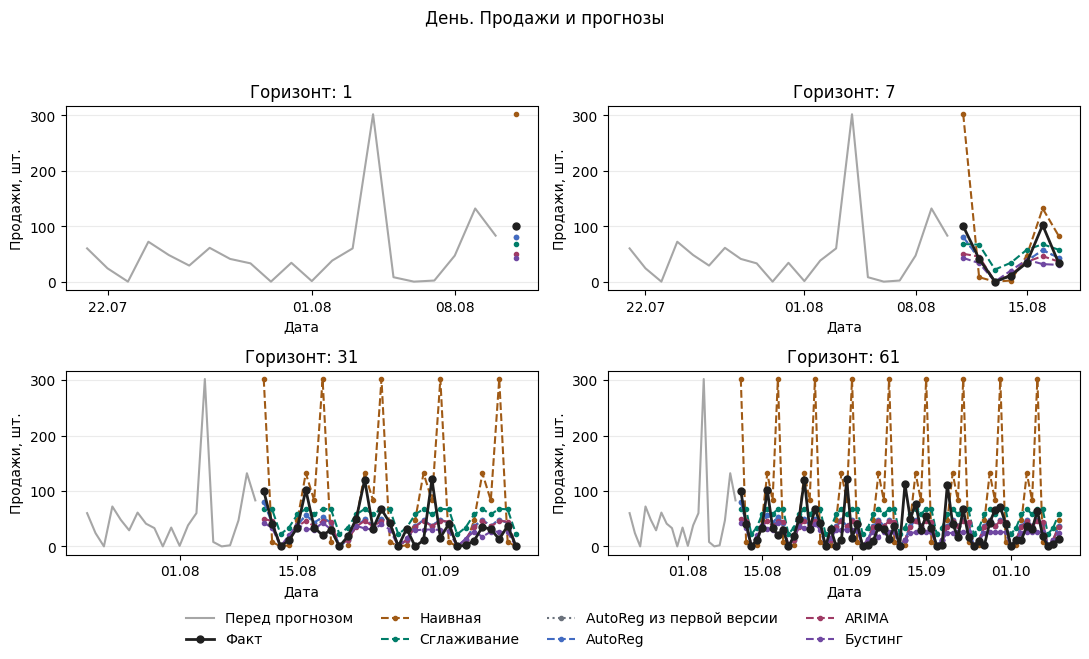

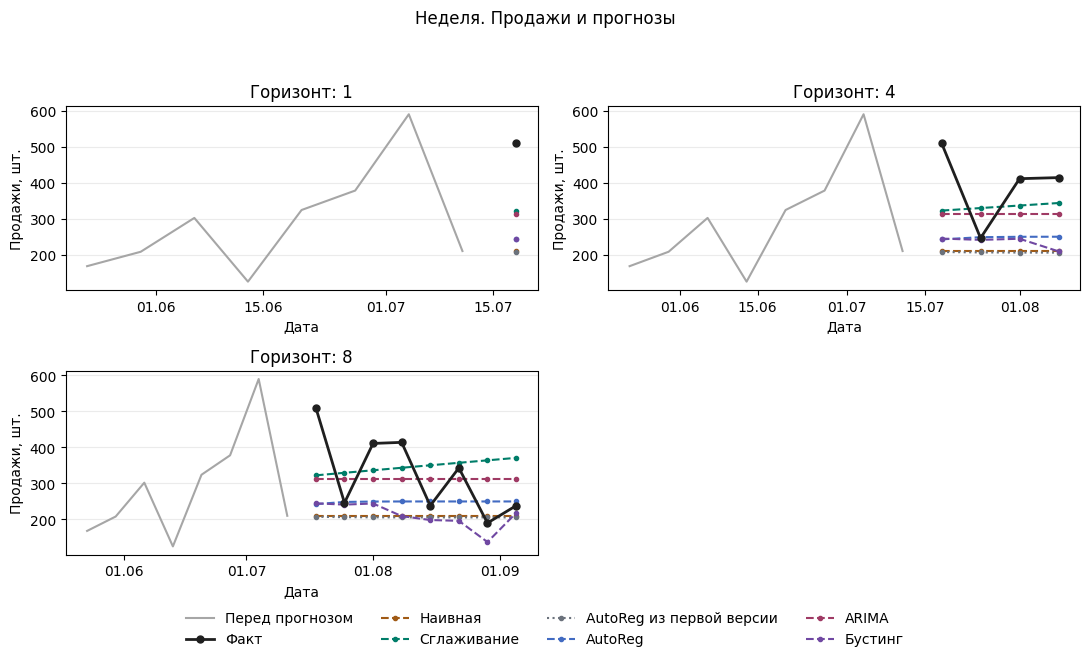

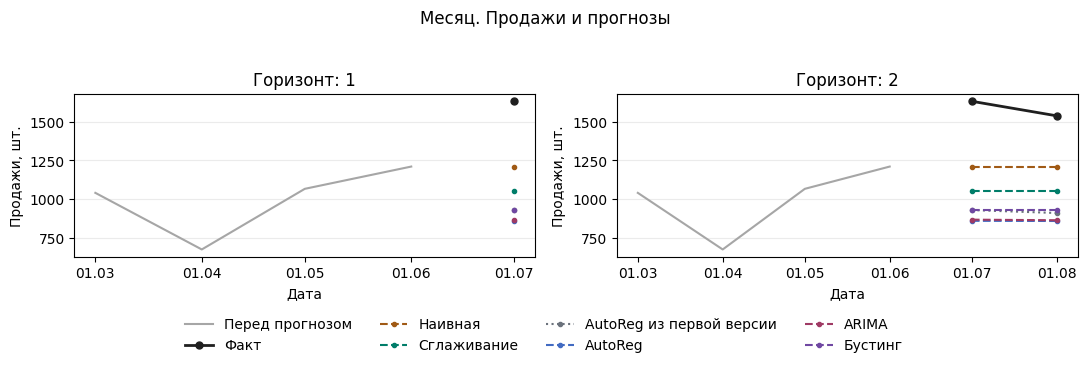

In [4]:
colors = dict(zip(MODELS, ["#a05a15", "#007d69", "#6b727c", "#426bc2", "#9f3a64", "#7048a2"]))


def plot_forecasts(predictions, series, label, horizons, lookback):
    data = predictions.loc[predictions["frequency"] == label]
    example = data.loc[data["cutoff"] == data["cutoff"].min()]
    history = series.loc[series.index < example["cutoff"].iloc[0]].tail(lookback)
    rows = (len(horizons) + 1) // 2
    fig, axes = plt.subplots(rows, 2, figsize=(11, 3 * rows + 0.6), squeeze=False)
    for ax, h in zip(axes.flat, horizons):
        path = example.loc[example["step"] <= h]
        actual = path.drop_duplicates("date")
        ax.plot(history.index, history, color="0.65", label="Перед прогнозом")
        ax.plot(actual["date"], actual["actual"], "o-", color="0.12",
                linewidth=2, markersize=5, label="Факт", zorder=10)
        for name, group in path.groupby("model", sort=False):
            ax.plot(group["date"], group["forecast"], "o:" if name == BASELINE else "o--", color=colors[name],
                    markersize=3, label=name)
        locator = mdates.AutoDateLocator(minticks=3, maxticks=6)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
        ax.set(title=f"Горизонт: {h}", xlabel="Дата", ylabel="Продажи, шт.")
        ax.grid(axis="y", alpha=0.25)
    for ax in list(axes.flat)[len(horizons):]:
        ax.set_visible(False)
    handles, names = axes[0, 0].get_legend_handles_labels()
    fig.suptitle(f"{label}. Продажи и прогнозы")
    fig.legend(handles, names, loc="lower center", ncol=4, frameon=False)
    fig.tight_layout(rect=(0, 0.13 / rows, 1, 0.94))
    plt.show()


for label, lookback in zip(settings, [21, 8, 4]):
    plot_forecasts(predictions, series[label], label, settings[label][2], lookback)

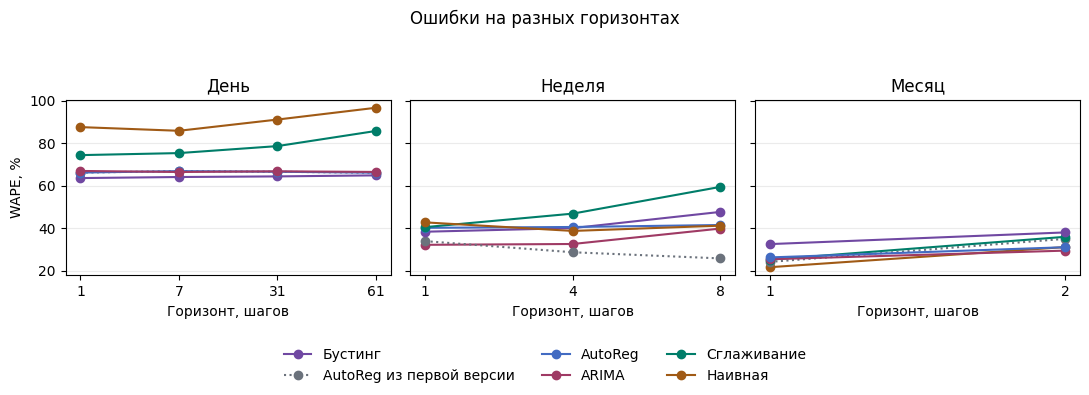

In [5]:
def plot_errors(metrics):
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.9), sharey=True)
    for ax, (label, (_, _, horizons, *_)) in zip(axes, settings.items()):
        subset = metrics.loc[metrics["frequency"] == label]
        for name, group in subset.groupby("model", sort=False):
            ax.plot(group["horizon"].astype(str), group["WAPE_pct"],
                    "o:" if name == BASELINE else "o-", color=colors[name], label=name)
        ax.set(title=label, xlabel="Горизонт, шагов", xticks=range(len(horizons)))
        ax.grid(axis="y", alpha=0.25)
    axes[0].set_ylabel("WAPE, %")
    handles, names = axes[0].get_legend_handles_labels()
    fig.suptitle("Ошибки на разных горизонтах")
    fig.legend(handles, names, loc="lower center", ncol=3, frameon=False)
    fig.tight_layout(rect=(0, 0.15, 1, 0.93))
    plt.show()


plot_errors(metrics)

## 5. Выводы

Сравниваю лучший результат каждой пары частота–горизонт со старой AutoReg, проверенной на том же тесте.

In [6]:
keys = ["frequency", "horizon"]
previous = metrics.loc[metrics["model"] == BASELINE, keys + ["WAPE_pct"]]
best = metrics.loc[metrics.groupby(keys, sort=False)["WAPE_pct"].idxmin()]
comparison = best.merge(previous, on=keys, suffixes=("", "_baseline"))
comparison["gain_pp"] = comparison["WAPE_pct_baseline"] - comparison["WAPE_pct"]

display(comparison[keys + ["model", "WAPE_pct", "WAPE_pct_baseline", "gain_pp"]].rename(columns={
    "frequency": "Частота", "horizon": "Горизонт", "model": "Модель",
    "WAPE_pct": "WAPE, %", "WAPE_pct_baseline": "Старая AutoReg, %",
    "gain_pp": "Выигрыш, п. п.",
}).round(2))

,Частота,Горизонт,Модель,"WAPE, %","Старая AutoReg, %","Выигрыш, п. п."
0,День,1,Бустинг,63.52,66.09,2.58
1,День,7,Бустинг,64.02,66.79,2.77
2,День,31,Бустинг,64.31,66.49,2.18
3,День,61,Бустинг,64.79,66.05,1.26
4,Неделя,1,ARIMA,32.11,33.84,1.73
5,Неделя,4,AutoReg из первой версии,28.60,28.60,0.00
6,Неделя,8,AutoReg из первой версии,25.71,25.71,0.00
7,Месяц,1,Наивная,21.57,24.07,2.49
8,Месяц,2,ARIMA,29.37,34.92,5.55


- **День.** Бустинг с 300 деревьями лучший на всех четырёх горизонтах. Его WAPE растёт с 63,52% до 64,79%. На графике видно, как наивная модель повторяет пик прошлой недели.
- **Неделя.** ARIMA выигрывает на одном шаге. На 4 и 8 шагах лучший результат у исходной AutoReg.
- **Месяц.** На одном шаге выигрывает наивная модель, на двух — ARIMA. Оценка опирается на 4–5 стартов.